In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal as mvn
from scipy.stats import binned_statistic_2d
from scipy.ndimage import zoom, gaussian_filter
from tqdm import tqdm
from inference_tools import ParticleFilter, crng, HilbertSorter, ConditionedBridge
from matplotlib import patches as mpatches
import matplotlib as mpl
from matplotlib import cm as cm
mpl.rcParams['figure.dpi'] = 120 #300

#plt.style.use('dark_background')

In [2]:
sorter = HilbertSorter(depth=9, dims=2)
bridge_gen = ConditionedBridge()

def collect_quantile(quantile, value, mass):
    value = value.flatten()
    mass = mass.flatten()
    srt_idx = np.argsort(value)
    value = value[srt_idx]
    mass = mass[srt_idx]
    mass_tot = np.sum(mass)
    prop = mass / mass_tot
    cumprop = np.cumsum(prop)
    midx = np.argmax(cumprop > quantile)
    return value[midx]

In [3]:
def abp_sde(T0, T1, X0, params):
    
    output_hires = params.get('output_hires', False)
    omit_bridges = params.get('omit_bridges', False)
    use_bridge_mean = params.get('use_bridge_mean', False)
    use_tqdm = params.get('use_tqdm', False)
    
    target_shift_X = params.get('target_shift_X', 0)
    target_shift_Y = params.get('target_shift_Y', 0)
    target_shift_P = params.get('target_shift_PHI', 0)
    target_slope_X = params.get('target_slope_X', 0)
    target_slope_Y = params.get('target_slope_Y', 0)
    target_slope_P = params.get('target_slope_PHI', 0)
    
    BridgeGen = params['BridgeGen']
    RNG = params['RNG']
    Dt  = params['Dt']
    Dr  = params['Dr']
    v   = params['v']
    _id = params.get('id', -1)
    
    dt  = params['dt']
    
    D = np.array([Dt, Dt, Dr])
    
    X = X0.copy()
    T = T0
    step = 0
    
    if output_hires:
        hires  = [X.copy()]
        hiresT = [T]
        
    n_steps = int((T1 - T0) / dt + 1)
    n_parts = X.shape[0]
    dt_ = (T1 - T0) / n_steps
    
    if not omit_bridges:
        
        offset_factor = 1 / (np.sqrt(Dr * dt_) * v) * n_steps
        
        shiftX = RNG.get(('abpsdeXshift', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_shift_X
        shiftY = RNG.get(('abpsdeYshift', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_shift_Y
        shiftP = RNG.get(('abpsdePshift', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_shift_P * offset_factor
        
        slopeX = RNG.get(('abpsdeXslope', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_slope_X
        slopeY = RNG.get(('abpsdeYslope', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_slope_Y
        slopeP = RNG.get(('abpsdePslope', _id, T0, T1), (n_parts,), corr=0.9999) * 0. + target_slope_P * offset_factor
        
        bridge_res_X = BridgeGen.get(n_steps + 1, shiftX, slopeX, ('abpsdeXbridgegen', _id, T0, T1), 0.0, RNG, use_bridge_mean)
        bridge_res_Y = BridgeGen.get(n_steps + 1, shiftY, slopeY, ('abpsdeYbridgegen', _id, T0, T1), 0.0, RNG, use_bridge_mean)
        bridge_res_P = BridgeGen.get(n_steps + 1, shiftP, slopeP, ('abpsdePbridgegen', _id, T0, T1), 0.0, RNG, use_bridge_mean)
        
        wX  = bridge_res_X['w']
        dwX = np.diff(wX, axis=0)
        dwX = np.concatenate([wX[[0],:], dwX])
        ddX = np.diff(dwX, axis=0).T
        
        wY  = bridge_res_Y['w']
        dwY = np.diff(wY, axis=0)
        dwY = np.concatenate([wY[[0],:], dwY])
        ddY = np.diff(dwY, axis=0).T
        
        wP  = bridge_res_P['w']
        dwP = np.diff(wP, axis=0)
        dwP = np.concatenate([wP[[0],:], dwP])
        ddP = np.diff(dwP, axis=0).T

        w = np.stack([ddX, ddY, ddP], axis=1)
        
    else:
        
        w = RNG.get(('abpsde_full', _id, T0, T1), (n_parts, 3, n_steps), corr=0) 

    if use_tqdm:
        R = tqdm(range(n_steps))
    else:
        R = range(n_steps)
        
    for k in R:

        ''' Integrate the EOM '''

        dx = np.cos(X[:, 2])
        dy = np.sin(X[:, 2])
        drift = np.stack([dx*v, dy*v, np.zeros_like(dx)], axis=1)

        X += np.sqrt(dt_) * w[..., k] * np.sqrt(D)
        X += dt_ * drift
        
        if output_hires:
            hires.append(X.copy())
            hiresT.append(T)
    
    res_dict = dict(X1=X)
    
    if output_hires:
        res_dict['per_particle_streams'] = dict(hires=np.stack(hires, -1))

    return res_dict

# Scatters

## Unconditioned

In [4]:
#%%time
N = int(1e6)
batch_size = 1000
dt = 1e-1
X0 = np.zeros((batch_size, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.5,
              v = 1,
              dt = dt,
              sigma_observation = 1e-0,
              output_hires=False,
              BridgeGen=bridge_gen,
              omit_bridges=True,
              use_tqdm = False,
             )

T_out = np.linspace(1, 4, 4)

x = []
y = []
for Tmax in T_out:
    xs = []
    ys = []
    for b_ in tqdm(range(N // batch_size)):
        params['RNG'].reroll(0)
        sim_res = abp_sde(0, Tmax, X0, params)
        xs.append(sim_res['X1'][:, 0])
        ys.append(sim_res['X1'][:, 1])
    x.append(np.concatenate(xs, axis=0))
    y.append(np.concatenate(ys, axis=0))
    
x = np.stack(x).T
y = np.stack(y).T

100%|████████████████████████████████████████████████████████████████████| 1000/1000 [00:03<00:00, 302.07it/s]


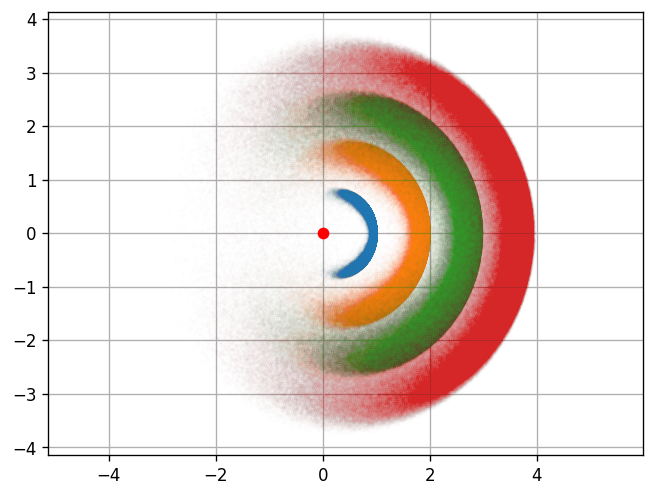

In [5]:
plt.plot(x,y,'.', alpha=0.1, markersize=0.1)
plt.plot([0],[0],'ro')
plt.gca().axis('equal')
plt.grid()
plt.show()

In [6]:
stats = []
nbins = 1000
edge_size = 0.1
for x_, y_ in zip(x.T, y.T):
    
    xmin, ymin = x_.min(), y_.min()
    xmax, ymax = x_.max(), y_.max()
    
    dx = xmax - xmin
    dy = ymax - ymin
    
    xmin -= edge_size * dx
    xmax += edge_size * dx
    ymin -= edge_size * dy
    ymax += edge_size * dy
    
    range_ = (xmin, xmax), (ymin, ymax)
    extent = xmin, xmax, ymin, ymax
    
    statistic = binned_statistic_2d(x_, y_, None, statistic='count', bins=nbins, range=range_)
    
    binx = (statistic.x_edge[1:] + statistic.x_edge[:-1]) / 2
    biny = (statistic.y_edge[1:] + statistic.y_edge[:-1]) / 2

    stats.append(dict(extent = extent,
                      statistic = statistic.statistic.T,
                      binx = binx,
                      biny = biny,
                     )
                )

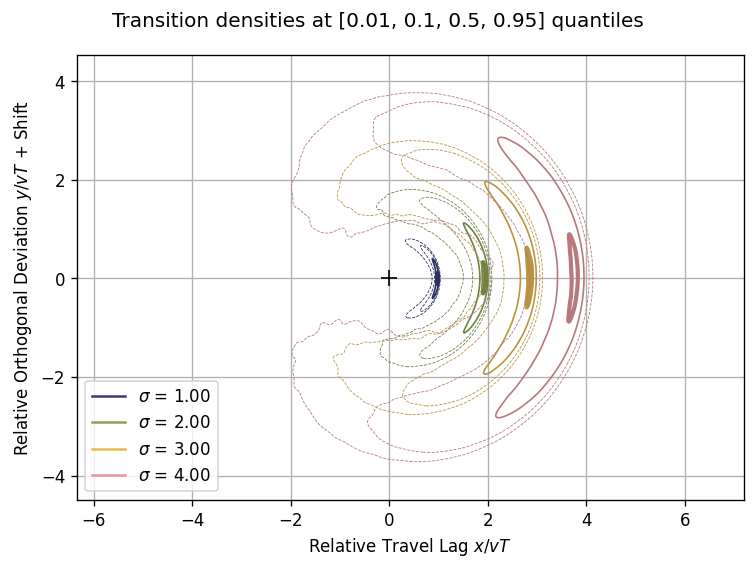

In [7]:
#plt.plot(x,y,'.k', alpha=0.1, markersize=0.1)

def collect_quantile(quantile, value, mass):
    value = value.flatten()
    mass = mass.flatten()
    srt_idx = np.argsort(value)
    value = value[srt_idx]
    mass = mass[srt_idx]
    mass_tot = np.sum(mass)
    prop = mass / mass_tot
    cumprop = np.cumsum(prop)
    midx = np.argmax(cumprop > quantile)
    return value[midx]

n_ = len(stats)
c = cm.tab20b(np.linspace(0,1,n_, endpoint=False))
for i, S in enumerate(stats):
    stat_filt = gaussian_filter(S['statistic'], 10)
    quantiles = [0.01, 0.10, 0.5, 0.95]
    levels = [collect_quantile(q, stat_filt, stat_filt) for q in quantiles]
    plt.plot([0],[0],color=c[i], label=f"$\sigma$ ={T_out[i] : .2f}")
    #plt.text(0.005, i / 100, f"$\sigma$ ={T_out[i] : .2f}")
    plt.contour(S['binx'], S['biny'] + i / 100, stat_filt, levels=levels, linestyles=['--', '--', '-', '-'], colors=[c[i]*[0.8,0.8,0.8,1]], linewidths=[0.5, 0.5, 1.0, 2.5])
    
plt.gca().axis('equal')
plt.plot([0],[0],'+k', markersize=10)
#plt.xlim((-.24, 0.06))
#plt.axvline(0, c='k')
#plt.ylim((-0.004, 0.038))
plt.legend(loc='lower left')
plt.grid()
plt.suptitle(f"Transition densities at {quantiles} quantiles")
plt.xlabel("Relative Travel Lag $x/vT$")
plt.ylabel("Relative Orthogonal Deviation $y/vT$ + Shift")
plt.tight_layout()
plt.show()

## Straight conditioning

In [8]:
#%%time
N = int(1e6)
batch_size = 1000
dt = 1e-1
X0 = np.zeros((batch_size, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.5,
              v = 1,
              dt = dt,
              sigma_observation = 1e-0,
              output_hires=False,
              BridgeGen=bridge_gen,
              omit_bridges=False,
              use_tqdm = False,
             )

T_out = np.linspace(1, 4, 4)

x = []
y = []
for Tmax in T_out:
    xs = []
    ys = []
    for b_ in tqdm(range(N // batch_size)):
        params['RNG'].reroll(0)
        sim_res = abp_sde(0, Tmax, X0, params)
        xs.append(sim_res['X1'][:, 0])
        ys.append(sim_res['X1'][:, 1])
    x.append(np.concatenate(xs, axis=0))
    y.append(np.concatenate(ys, axis=0))
    
x = np.stack(x).T
y = np.stack(y).T

100%|████████████████████████████████████████████████████████████████████| 1000/1000 [00:09<00:00, 105.32it/s]


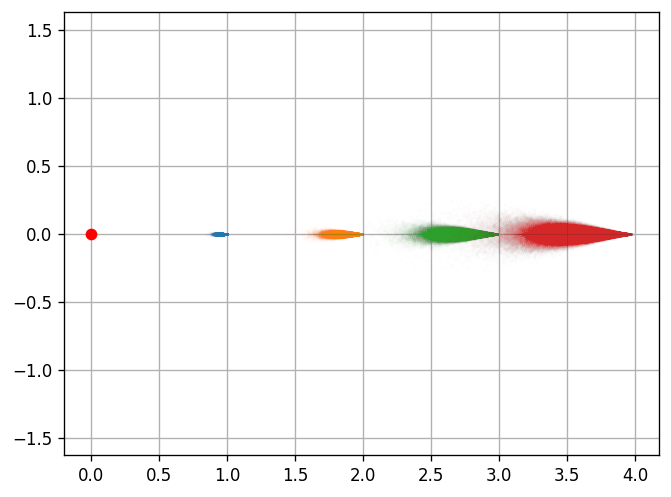

In [9]:
plt.plot(x,y,'.', alpha=0.1, markersize=0.1)
plt.plot([0],[0],'ro')
plt.gca().axis('equal')
plt.grid()
plt.show()

In [10]:
stats = []
nbins = 1000
edge_size = 0.1
for x_, y_ in zip(x.T, y.T):
    
    xmin, ymin = x_.min(), y_.min()
    xmax, ymax = x_.max(), y_.max()
    
    dx = xmax - xmin
    dy = ymax - ymin
    
    xmin -= edge_size * dx
    xmax += edge_size * dx
    ymin -= edge_size * dy
    ymax += edge_size * dy
    
    range_ = (xmin, xmax), (ymin, ymax)
    extent = xmin, xmax, ymin, ymax
    
    statistic = binned_statistic_2d(x_, y_, None, statistic='count', bins=nbins, range=range_)
    
    binx = (statistic.x_edge[1:] + statistic.x_edge[:-1]) / 2
    biny = (statistic.y_edge[1:] + statistic.y_edge[:-1]) / 2

    stats.append(dict(extent = extent,
                      statistic = statistic.statistic.T,
                      binx = binx,
                      biny = biny,
                     )
                )

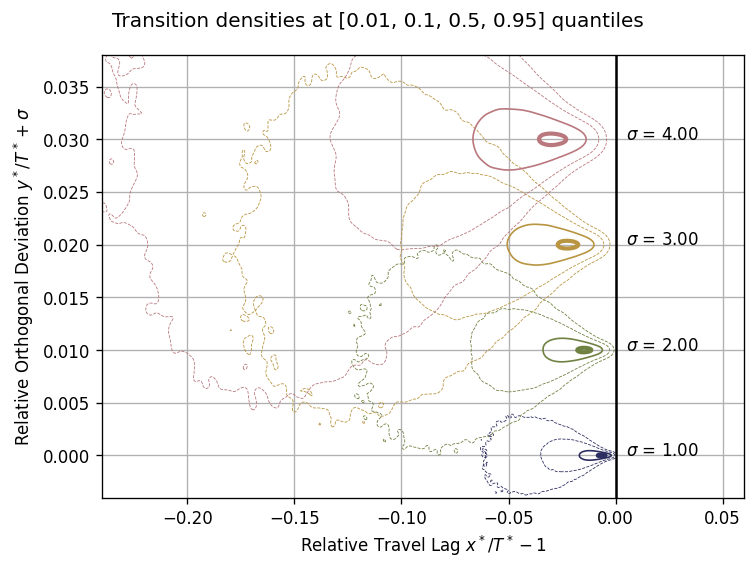

In [11]:
#plt.plot(x,y,'.k', alpha=0.1, markersize=0.1)
n_ = len(stats)
c = cm.tab20b(np.linspace(0,1,n_, endpoint=False))
for i, S in enumerate(stats):
    stat_filt = gaussian_filter(S['statistic'], 3)
    quantiles = [0.01, 0.10, 0.5, 0.95]
    levels = [collect_quantile(q, stat_filt, stat_filt) for q in quantiles]
    plt.text(0.005, i / 100, f"$\sigma$ ={T_out[i] : .2f}")
    plt.contour((S['binx']-T_out[i])/T_out[i], 1/T_out[i] * S['biny'] + i / 100, stat_filt, levels=levels, linestyles=['--', '--', '-', '-'], colors=[c[i]*[0.8,0.8,0.8,1]], linewidths=[0.5, 0.5, 1.0, 2.5])
    
#plt.gca().axis('equal')
#plt.plot([0],[0],'+k', markersize=10)
plt.xlim((-.24, 0.06))
plt.axvline(0, c='k')
plt.ylim((-0.004, 0.038))
#plt.legend(loc='lower left')
plt.grid()
plt.suptitle(f"Transition densities at {quantiles} quantiles")
plt.xlabel("Relative Travel Lag $x^*/T^*-1$")
plt.ylabel("Relative Orthogonal Deviation $y^*/T^*+\sigma$")
plt.tight_layout()
plt.show()

## Angled

In [12]:
#%%time
N = int(1e7)
batch_size = 1000
dt = 1e-1
T_out = np.linspace(1, 4, 4)


params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.5,
              v = 1,
              dt = dt,
              sigma_observation = 1e-0,
              output_hires=False,
              BridgeGen=bridge_gen,
              omit_bridges=False,
              use_tqdm = False,
              target_shift_PHI=0,
              target_slope_PHI=0.0,
              use_bridge_mean=False,
             )

''' FULL RUN '''

X0 = np.zeros((batch_size, 3)) + [0,0,0]

x = []
y = []
for Tmax in T_out:
    xs = []
    ys = []
    for b_ in tqdm(range(N // batch_size)):
        params['RNG'].reroll(0)
        sim_res = abp_sde(0, Tmax, X0, params)
        xs.append(sim_res['X1'][:, 0])
        ys.append(sim_res['X1'][:, 1])
    x.append(np.concatenate(xs, axis=0))
    y.append(np.concatenate(ys, axis=0))
    
x = np.stack(x).T
y = np.stack(y).T


''' TARGETS'''

params['use_bridge_mean'] = True
params['RNG'] = crng(212)
X0 = np.zeros((1, 3)) + [0,0,0]

x_targ = []
y_targ = []
for Tmax in T_out:
    params['RNG'].reroll(0)
    sim_res = abp_sde(0, Tmax, X0, params)
    x_targ.append(sim_res['X1'][:, 0])
    y_targ.append(sim_res['X1'][:, 1])
    
x_targ = np.stack(x_targ).T
y_targ = np.stack(y_targ).T

d_targ = np.sqrt(x_targ**2 + y_targ**2).flatten()

100%|██████████████████████████████████████████████████████████████████| 10000/10000 [01:32<00:00, 108.38it/s]


In [13]:
stats = []
nbins = 1000
edge_size = 0.1
for x_, y_ in zip((x-x_targ).T, (y-y_targ).T):
    
    xmin, ymin = x_.min(), y_.min()
    xmax, ymax = x_.max(), y_.max()
    
    dx = xmax - xmin
    dy = ymax - ymin
    
    xmin -= edge_size * dx
    xmax += edge_size * dx
    ymin -= edge_size * dy
    ymax += edge_size * dy
    
    range_ = (xmin, xmax), (ymin, ymax)
    extent = xmin, xmax, ymin, ymax
    
    statistic = binned_statistic_2d(x_, y_, None, statistic='count', bins=nbins, range=range_)
    
    binx = (statistic.x_edge[1:] + statistic.x_edge[:-1]) / 2
    biny = (statistic.y_edge[1:] + statistic.y_edge[:-1]) / 2

    stats.append(dict(extent = extent,
                      statistic = statistic.statistic.T,
                      binx = binx,
                      biny = biny,
                     )
                )

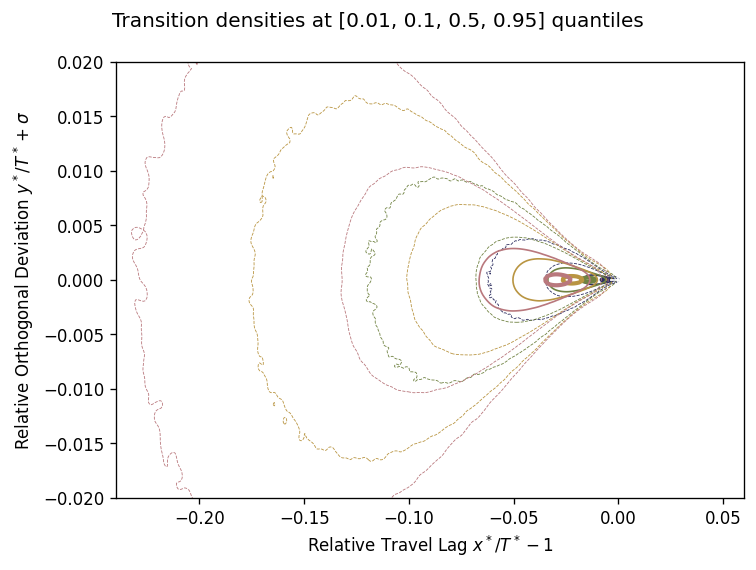

In [14]:
n_ = len(stats)
c = cm.tab20b(np.linspace(0,1,n_, endpoint=False))
for i, S in enumerate(stats):
    stat_filt = gaussian_filter(S['statistic'], 2)
    quantiles = [0.01, 0.10, 0.5, 0.95]
    levels = [collect_quantile(q, stat_filt, stat_filt) for q in quantiles]
    #plt.text(0.005, i / 100, f"$\sigma$ ={T_out[i] : .2f}")
    plt.contour(S['binx'] / d_targ[i], S['biny'] / d_targ[i] + 0/100, stat_filt, levels=levels, linestyles=['--', '--', '-', '-'], colors=[c[i]*[0.8,0.8,0.8,1]], linewidths=[0.5, 0.5, 1.0, 2.5])
    
#plt.gca().axis('equal')
plt.plot([0],[0],'+w', markersize=10)
plt.xlim((-.24, 0.06))
#plt.axvline(0, c='k')
plt.ylim((-0.02, 0.02))
#plt.legend(loc='lower left')
#plt.grid()
plt.suptitle(f"Transition densities at {quantiles} quantiles")
plt.xlabel("Relative Travel Lag $x^*/T^*-1$")
plt.ylabel("Relative Orthogonal Deviation $y^*/T^*+\sigma$")
plt.tight_layout()
plt.show()

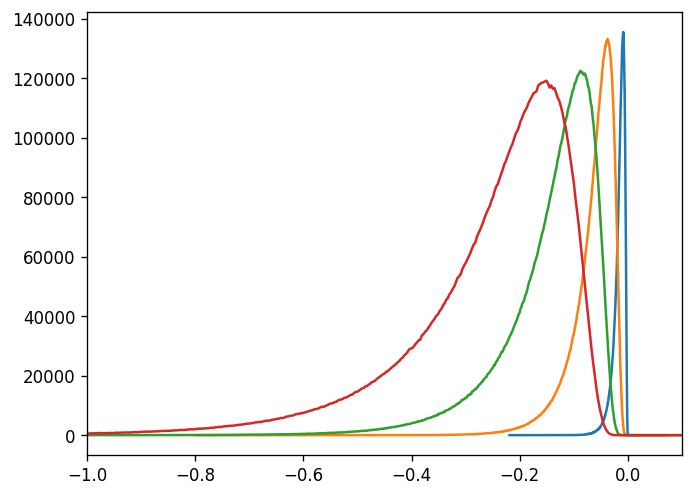

In [15]:
for i, S in enumerate(stats):
    plt.plot(S['binx'], np.sum(S['statistic'], axis=0))
plt.xlim([-1, 0.1])
plt.show()

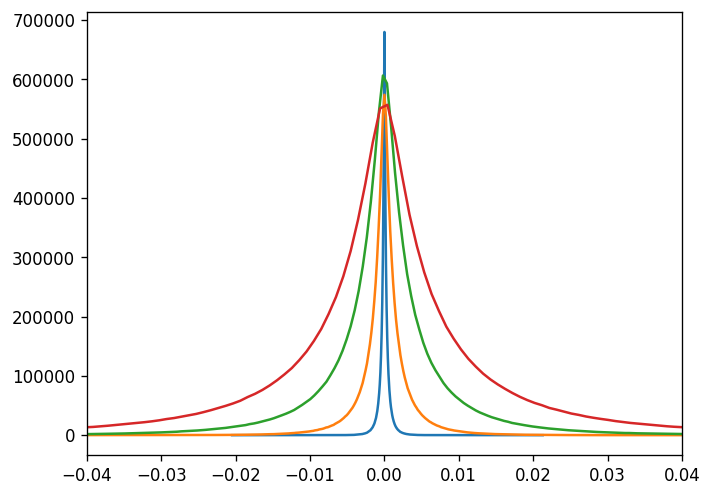

In [16]:
for i, S in enumerate(stats):
    plt.plot(S['biny'], np.sum(S['statistic'], axis=1))
plt.xlim([-0.04, 0.04])
plt.show()

In [17]:
N = 1000
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 10,
              v = 1,
              dt = 1e-3,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
              
             )
params['target_slope_PHI'] = 1
params['target_shift_PHI'] = 0
sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
sim_res = abp_sde(0, 1, X0, params)

x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]

In [18]:
params['RNG'].reroll(0.9)
#params['target_shift_PHI'] = 0.1
#params['target_slope_PHI'] = 0
#params['v'] *= 1.3
sim_res = abp_sde(0, 1, X0, params)
x2 = sim_res['per_particle_streams']['hires'][:,0,:]
y2 = sim_res['per_particle_streams']['hires'][:,1,:]

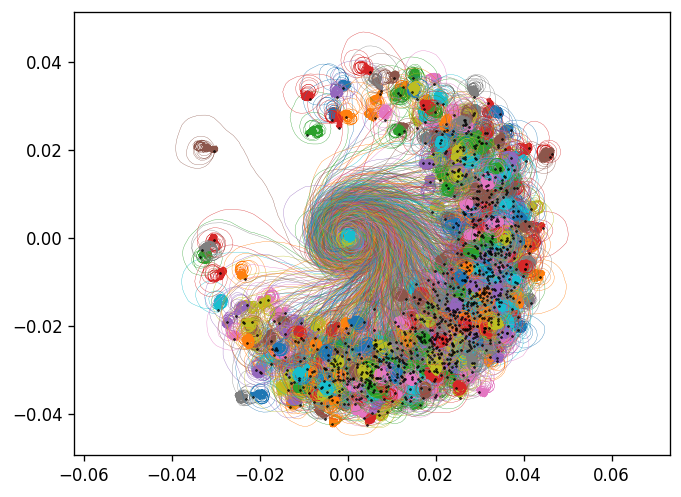

In [19]:
plt.plot(x1.T,y1.T, linewidth=0.2, alpha=1)
plt.plot(x1[...,-1].T,y1[...,-1].T, '.k', markersize=1)
#plt.plot(x2.T,y2.T, 'g', linewidth=1, alpha=1)
#plt.plot(x2[...,-1].T,y2[...,-1].T, '.w', markersize=2)
plt.gca().axis('equal')
#plt.ylim([-0.5,0.1])
plt.show()

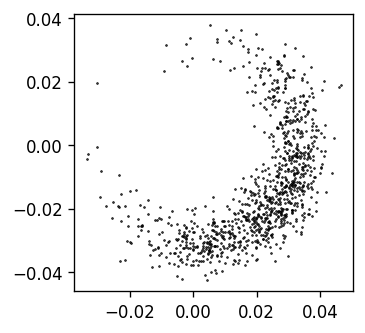

In [20]:
plt.figure(figsize=(3,3))
plt.plot(x1[...,-1].T, y1[...,-1].T, '.k', markersize=1)
#plt.plot(x2[...,-1].T + 0.01, y2[...,-1].T, '.g', markersize=3)
plt.gca().axis('equal')
plt.show()

In [21]:
def abp_logl(X, Y, params):
    sigma = params['sigma_observation']
    return np.nansum( -((X - Y) / sigma) ** 2, axis=1)

In [22]:
N = 100
X0 = np.zeros((N, 3)) + [0,0,0] + 0 * np.random.randn(N, 3) * [0.01, 0.01, np.pi/20]

In [23]:
Yorient_orig = [dict(T=1, Y=[1, .5,  np.nan], target_shift_PHI=0, target_slope_PHI=0.0),
                dict(T=2, Y=[2, 1, np.nan], target_shift_PHI=0., target_slope_PHI=0),
                #dict(T=4, Y=[4, -0.,  np.nan], target_shift_PHI=-.0, target_slope_PHI=0),
          ]

params_orig = dict(RNG=crng(121),
              Dt = 0,
              Dr = 1e-2,
              v = 1,
              dt = 1e-2,
              HilbertSort_dims = (0,1),
              HilbertSorter = sorter,
              sigma_observation = 4e-2,
              output_hires=True,
              output_trajectory=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
              HilbertSort_useObservationCenter = False,
              observation_parameters = ['target_shift_PHI', 'target_slope_PHI'],
              observation_parameter_adapt_rate = dict(target_shift_PHI=0.005, target_slope_PHI=0.0001)
             )

  0%|                                                                                | 0/1000 [00:00<?, ?it/s]~/PHD/Research/PMMH/inference_tools.py:510: RuntimeWarning: divide by zero encountered in log
  result['logl'] += np.log(np.sum(W)) # Update likelihood estimate
~/PHD/Research/PMMH/inference_tools.py:120: RuntimeWarning: invalid value encountered in divide
  p = w / np.sum(w)                   # Normalized PDF
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
~/PHD/Research/PMMH/inference_tools.py:510: RuntimeWarning: divide by zero encountered in log
  result['logl'] += np.log(np.sum(W)) # Update likelihood estimate
~/PHD/Research/PMMH/inference_tools.py:120: RuntimeWarning: invalid value encountered in divide
  p = w / np.sum(w)                   # Normalized PDF
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_76883/1153910509.py:31: RuntimeWarning: invalid value encountered in double_scalars
  thresh = 1 if logl_propo

accept =  1000
1.227393533901522


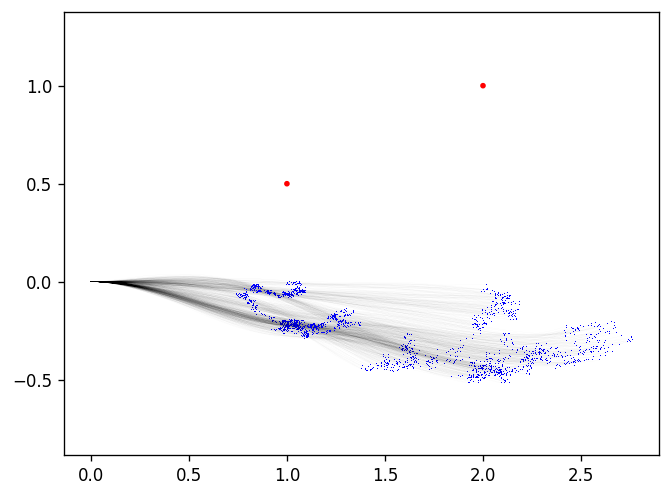

(array([ 42.,  70.,  50., 118., 154., 192., 205., 112.,  37.,  20.]),
 array([0.00989882, 0.01018074, 0.01046266, 0.01074458, 0.0110265 ,
        0.01130842, 0.01159035, 0.01187227, 0.01215419, 0.01243611,
        0.01271803]),
 <BarContainer object of 10 artists>)

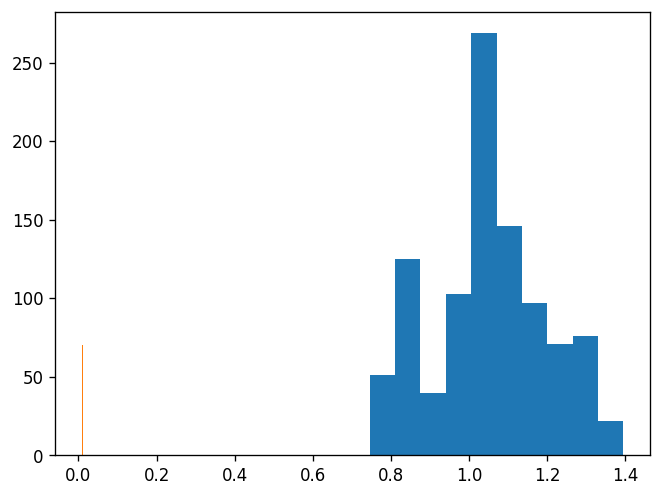

In [24]:
Yorient = Yorient_orig
params = params_orig

logl = -np.inf
accept = 0
params['sigma_observation'] = 1e-2
#params['target_shift_PHI'] = 0.001
#params['target_slope_PHI'] = 0.00001

Drpost = []
vpost = []

for _ in tqdm(range(1000)):
    params['RNG'].reroll()
    old_v = params['v']
    old_Dr = params['Dr']
    
    params['v'] *= (1 + np.random.randn() * 0.01)
    params['Dr'] *= (1 + np.random.randn() * 0.01)
    
    for param_name in params['observation_parameters']:
        for i, yt_ in enumerate(Yorient):
            Yorient[i][param_name + '_old'] = Yorient[i][param_name]
            Yorient[i][param_name] += np.random.randn() * params["observation_parameter_adapt_rate"][param_name]

    
    filt_res = ParticleFilter(abp_logl, abp_sde, X0, Yorient, params)
    
    logl_propose = filt_res['logl']
    a = np.random.rand()
    thresh = 1 if logl_propose > logl else np.exp(logl_propose - logl)
    if a > thresh:
        params['v'] = old_v
        
        for param_name in params['observation_parameters']:
            for i, yt_ in enumerate(Yorient):
                Yorient[i][param_name] = Yorient[i][param_name + '_old']
        
        params['Dr'] = old_Dr
        params['RNG'].revert()
    else:
        accept += 1
        logl = logl_propose
        r = filt_res['streams']['hires']
        
    filt_res['trajectory']
    plt.plot(r[0,:], r[1,:], 'k', alpha=0.05, linewidth=0.1)
    plt.plot(filt_res['trajectory'][0,:], filt_res['trajectory'][1,:], ',b')
    vpost.append(params['v'])
    Drpost.append(params['Dr'])
    
print("accept = ", accept)
#plt.gca().axis('equal')
for yt_ in Yorient:
    y = yt_['Y']
    circ = mpatches.Circle(y[:2], radius=params['sigma_observation'], color='r', zorder=0,)
    plt.gca().add_patch(circ)

plt.xlim([-0.1, 4.2])
print(params['v'])
#print(Yorient[1]['target_shift_PHI'])
#plt.ylim([-0.4, 0.6])
plt.gca().axis('equal')
plt.show()
plt.hist(vpost)
plt.hist(Drpost)

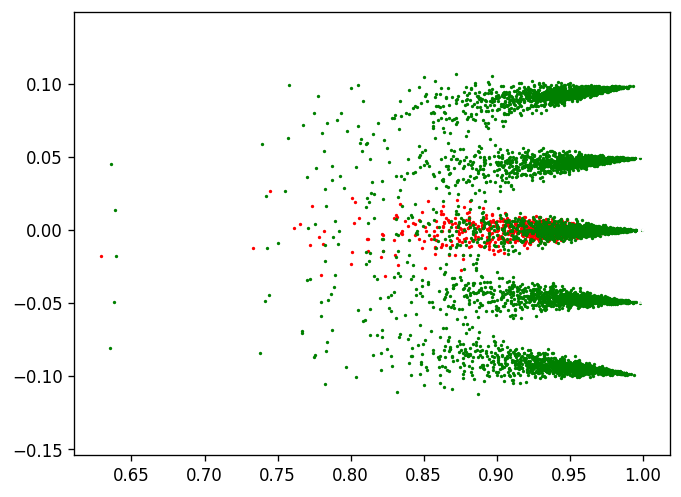

In [25]:
N = 1300
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 2,
              v = 1,
              dt = 1e-3,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1[...,-1].T, y1[...,-1].T, '.r', markersize=2)
for offset in np.linspace(-0.1,0.1, 5):  
    params['target_shift_PHI'] = offset
    sim_res = abp_sde(0, 1, X0, params)
    x2 = sim_res['per_particle_streams']['hires'][:,0,:]
    y2 = sim_res['per_particle_streams']['hires'][:,1,:]
    plt.plot(x2[...,-1].T + 0.01, y2[...,-1].T, '.g', markersize=2)
    plt.plot([1],[offset], '+w')
    plt.gca().axis('equal')
plt.show()

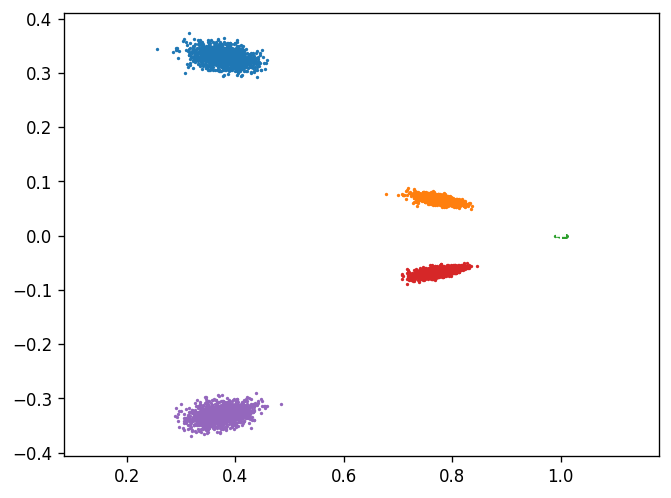

In [26]:
N = 1300
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 0.1,
              v = 1,
              dt = 1e-3,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]

for offset in np.linspace(-0.1,0.1, 5)*0.04:  
    params['target_slope_PHI'] = offset
    sim_res = abp_sde(0, 1, X0, params)
    x2 = sim_res['per_particle_streams']['hires'][:,0,:]
    y2 = sim_res['per_particle_streams']['hires'][:,1,:]
    
    #plt.plot(x1[...,-1].T, y1[...,-1].T, '.r', markersize=2)
    plt.plot(x2[...,-1].T + 0.01, y2[...,-1].T, '.', markersize=2)
    plt.plot([1],[offset], '+w')
    plt.gca().axis('equal')
plt.show()

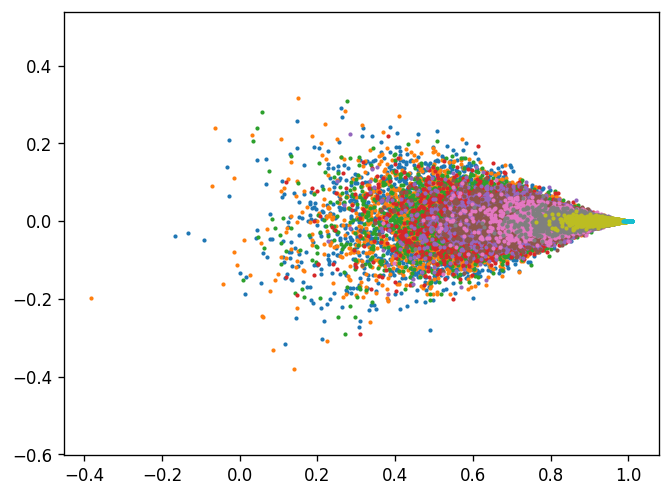

In [27]:
N = 13000
X0 = np.zeros((N, 3)) + [0,0,0]
params = dict(RNG=crng(121),
              Dt = 0,
              Dr = 2,
              v = 1,
              dt = 1e-2,
              sigma_observation = 1e-0,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
             )

sim_res = abp_sde(0, 1, X0, params)
x1 = sim_res['per_particle_streams']['hires'][:,0,:]
y1 = sim_res['per_particle_streams']['hires'][:,1,:]
plt.plot(x1[...,-1].T, y1[...,-1].T, '.r', markersize=2)
for Dr in np.linspace(10, 0.1, 10):
    params['RNG'].reroll(0)
    params['Dr'] = Dr
    sim_res = abp_sde(0, 1, X0, params)
    x2 = sim_res['per_particle_streams']['hires'][:,0,:]
    y2 = sim_res['per_particle_streams']['hires'][:,1,:]
    plt.plot(x2[...,-1].T + 0.01, y2[...,-1].T, '.', markersize=3, alpha=1)
    plt.gca().axis('equal')
plt.show()